# Supply Chain Analytics & Transportation Optimization
Step-by-step analysis notebook. Data is **synthetic** (see `src/generate_data.py`).

In [1]:
import sys, os; os.chdir('..'); sys.path.insert(0, 'src')
import pandas as pd, matplotlib.pyplot as plt
import optimize as op
wh, cu, sh, dm = op.load()
sh.head()

,order_id,order_date,warehouse,customer,product_category,priority,quantity,vehicle_type,distance_km,transport_cost,promised_days,delivery_days,delayed
0,1,2024-01-08,WH-Delhi,Jaipur,Electronics,Express,25,Small,305.6,891.67,2,3,1
1,2,2024-01-18,WH-Delhi,Jaipur,Electronics,Standard,8,Small,305.6,829.34,3,2,0
2,3,2024-01-16,WH-Delhi,Jaipur,Electronics,Standard,131,Medium,305.6,1280.37,3,2,0
3,4,2024-01-05,WH-Nagpur,Jaipur,FMCG,Standard,127,Medium,939.6,2231.93,4,3,0
4,5,2024-01-20,WH-Delhi,Jaipur,FMCG,Standard,281,Medium,305.6,1830.41,3,2,0


## 1. Data overview

In [2]:
print(sh.shape); print(sh.dtypes); sh.describe().round(1)

(4363, 13)
order_id                     int64
order_date          datetime64[us]
warehouse                      str
customer                       str
product_category               str
priority                       str
quantity                     int64
vehicle_type                   str
distance_km                float64
transport_cost             float64
promised_days                int64
delivery_days                int64
delayed                      int64
dtype: object


,order_id,order_date,quantity,distance_km,transport_cost,promised_days,delivery_days,delayed
count,4363.0,4363,4363.0,4363.0,4363.0,4363.0,4363.0,4363.0
mean,2182.0,2024-12-29 02:27:51.693788,98.9,683.7,1573.4,3.4,2.6,0.1
min,1.0,2024-01-01 00:00:00,1.0,156.6,803.2,1.0,1.0,0.0
25%,1091.5,2024-06-26 12:00:00,26.0,378.9,965.1,3.0,2.0,0.0
50%,2182.0,2025-01-01 00:00:00,62.0,571.1,1233.4,3.0,2.0,0.0
75%,3272.5,2025-06-28 00:00:00,132.0,869.4,1800.8,4.0,3.0,0.0
max,4363.0,2025-12-28 00:00:00,1364.0,1897.7,10951.0,6.0,8.0,1.0
std,1259.6,NaN,115.9,374.5,995.5,0.9,1.3,0.3


## 2. Demand trend

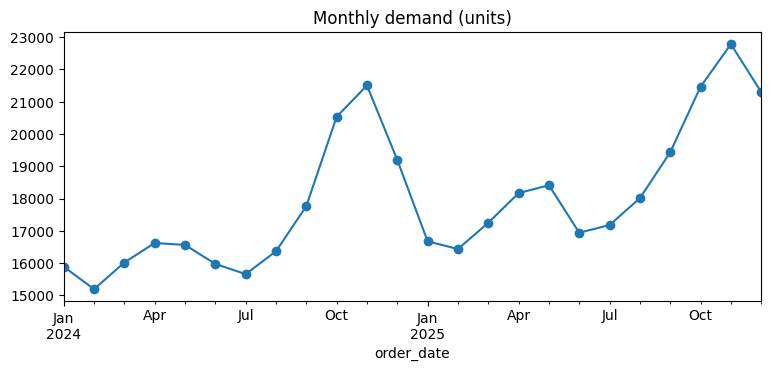

In [3]:
m = sh.groupby(sh.order_date.dt.to_period('M')).quantity.sum()
m.plot(figsize=(9,3.5), marker='o', title='Monthly demand (units)'); plt.show()

## 3. Delays by priority and warehouse

priority
Express     32.6
Standard     9.4
Name: delayed, dtype: float64


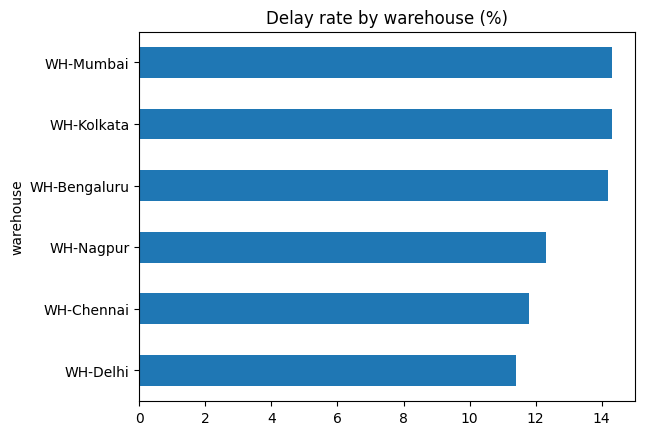

In [4]:
print((sh.groupby('priority').delayed.mean()*100).round(1))
(sh.groupby('warehouse').delayed.mean()*100).round(1).sort_values().plot.barh(title='Delay rate by warehouse (%)'); plt.show()

## 4. Optimise the peak month (PuLP)

In [5]:
dem, month, year = op.peak_demand(sh)
opt = op.solve_transport(wh, dem, dm); base = op.greedy_baseline(wh, dem, dm)
print(f'Peak: {year}-{month:02d}, {dem.sum():,.0f} units')
print('Greedy baseline INR', round(op.plan_cost(base, dm)))
print('PuLP optimised  INR', round(op.plan_cost(opt, dm)))

Peak: 2025-11, 22,778 units
Greedy baseline INR 159734
PuLP optimised  INR 123063


## 5. Allocation plan

In [6]:
M = pd.DataFrame(0.0, index=wh.index, columns=cu.index)
for (w, c), q in opt.items(): M.loc[w, c] = q
M.round().astype(int)

customer,Jaipur,Lucknow,Chandigarh,Ahmedabad,Pune,Hyderabad,Kochi,Patna,Bhopal,Guwahati,Bhubaneswar,Coimbatore,Indore,Surat,Visakhapatnam,Ranchi,Dehradun,Raipur
warehouse,,,,,,,,,,,,,,,,,,
WH-Delhi,1640,1438,1087,128,0,0,0,0,0,0,0,0,0,0,0,0,603,0
WH-Mumbai,0,0,0,1912,2316,0,0,0,0,0,0,0,0,1372,0,0,0,0
WH-Chennai,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1022,0,0,0
WH-Kolkata,0,0,0,0,0,0,0,1313,0,802,960,0,0,0,0,815,0,0
WH-Nagpur,0,0,0,0,0,306,0,0,1055,0,0,0,1125,0,0,0,0,914
WH-Bengaluru,0,0,0,0,0,2136,939,0,0,0,0,895,0,0,0,0,0,0


## 6. What-if scenarios

In [7]:
op.scenarios(wh, dem, dm)

,scenario,feasible,cost_inr,units,capacity,cost_change_pct
0,Base (peak month),True,123063,22778,27200,0.00
1,Demand +5%,True,130967,23916,27200,6.42
2,Demand +10%,True,140476,25055,27200,14.15
3,Demand +15%,True,153744,26194,27200,24.93
4,WH-Delhi at 50% capacity,True,148285,22778,24400,20.50
5,WH-Mumbai at 50% capacity,True,146022,22778,24400,18.66
6,WH-Chennai at 50% capacity,True,123063,22778,25050,0.00
7,WH-Kolkata at 50% capacity,True,136435,22778,25050,10.87
8,WH-Nagpur at 50% capacity,True,132283,22778,25500,7.49
9,WH-Bengaluru at 50% capacity,True,123527,22778,25200,0.38


## 7. Inventory policy

In [8]:
op.inventory_policy(sh, cu, dm, opt)

,customer,main_warehouse,lead_time_days,avg_daily_demand,safety_stock,reorder_point
0,Jaipur,WH-Delhi,1.7,39.6,13,79
1,Lucknow,WH-Delhi,2.2,35.8,12,91
2,Chandigarh,WH-Delhi,1.7,28.3,9,57
3,Ahmedabad,WH-Mumbai,2.3,54.0,18,141
4,Pune,WH-Mumbai,1.3,56.7,17,93
5,Hyderabad,WH-Bengaluru,2.4,67.8,23,188
6,Kochi,WH-Bengaluru,2.1,25.2,7,59
7,Patna,WH-Kolkata,2.4,32.0,11,86
8,Bhopal,WH-Nagpur,1.8,28.6,9,62
9,Guwahati,WH-Kolkata,2.5,21.3,7,60
